# Exploration of h5 file



In [26]:
# %% load k-space data, display rsos combination across coils for all slices

from matplotlib import pyplot as plt
import scipy.io as sio
# load LIBRARY file with defined functions
import LIBRARY as lib

import numpy as np
import sigpy as sp

import sigpy.mri as mri
import sigpy.mri.app as app

import h5py
import lxml.etree as etree

# Loading file, getting k space data

## Infos regarding h5 file and h (py package)
.h5 files opened as h5py.File. <br>
File ows 3 keys : ['ismrmrd_header', 'kspace', 'reconstruction_rss'] <br>
[ISMRM Data Format  (MRD)](https://ismrmrd.readthedocs.io/en/latest/) <br>
In the 'ismrmrd_header' are informations about the configuration of the IRM acquisition as xml file. <br>
'kspace' data and 'reconstruction_rss' are also available


In [18]:
#loading .h5 file with The h5py package (Pythonic interface to the HDF5 binary data format) as a h5py._hl.files.File
file_name = 'file_brain_AXT2_205_2050058.h5'
image_file = h5py.File(file_name)

type(image_file)

/data_local/data_hdd/lehmansy/tmp/ipykernel_3762118/1183610211.py:3: H5pyDeprecationWarning: The default file mode will change to 'r' (read-only) in h5py 3.0. To suppress this warning, pass the mode you need to h5py.File(), or set the global default h5.get_config().default_file_mode, or set the environment variable H5PY_DEFAULT_READONLY=1. Available modes are: 'r', 'r+', 'w', 'w-'/'x', 'a'. See the docs for details.
  image_file = h5py.File(file_name)


h5py._hl.files.File

In [19]:
list(image_file.keys())

['ismrmrd_header', 'kspace', 'reconstruction_rss']

In [20]:
header = image_file['ismrmrd_header'][()]
header

b'<?xml version="1.0" encoding="utf-8"?>\n<ismrmrdHeader xmlns="http://www.ismrm.org/ISMRMRD" xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.ismrm.org/ISMRMRD ismrmrd.xsd">\n   <studyInformation>\n      <studyTime>17:12:13</studyTime>\n   </studyInformation>\n   <measurementInformation>\n      <measurementID>141513_2549038_2549046_561</measurementID>\n      <patientPosition>HFS</patientPosition>\n      <protocolName>AX</protocolName>\n      <frameOfReferenceUID>1.3.12.2.1107.5.2.18.141513.1.20180208164929957.0.0.5009</frameOfReferenceUID>\n   </measurementInformation>\n   <acquisitionSystemInformation>\n      <systemVendor>SIEMENS</systemVendor>\n      <systemModel>Aera</systemModel>\n      <systemFieldStrength_T>1.494</systemFieldStrength_T>\n      <relativeReceiverNoiseBandwidth>0.793</relativeReceiverNoiseBandwidth>\n      <receiverChannels>20</receiverChannels>\n      <coilLabel>\n         <coilNumber

In [23]:
type(image_file['ismrmrd_header'])

h5py._hl.dataset.Dataset

In [25]:
x = etree.parse(header)
etree.tostring(x, pretty_print=True)

OSError: Error reading file '<?xml version="1.0" encoding="utf-8"?>
<ismrmrdHeader xmlns="http://www.ismrm.org/ISMRMRD" xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.ismrm.org/ISMRMRD ismrmrd.xsd">
   <studyInformation>
      <studyTime>17:12:13</studyTime>
   </studyInformation>
   <measurementInformation>
      <measurementID>141513_2549038_2549046_561</measurementID>
      <patientPosition>HFS</patientPosition>
      <protocolName>AX</protocolName>
      <frameOfReferenceUID>1.3.12.2.1107.5.2.18.141513.1.20180208164929957.0.0.5009</frameOfReferenceUID>
   </measurementInformation>
   <acquisitionSystemInformation>
      <systemVendor>SIEMENS</systemVendor>
      <systemModel>Aera</systemModel>
      <systemFieldStrength_T>1.494</systemFieldStrength_T>
      <relativeReceiverNoiseBandwidth>0.793</relativeReceiverNoiseBandwidth>
      <receiverChannels>20</receiverChannels>
      <coilLabel>
         <c

## Informations from header
number of coils : 20 is in receiverChannels section <br>
matrixSize 640 x; y 320; z1 in  encoding and encodedSpace section <br>
reconSpace : matrixSize :x 320; 320 y; z >1 <br>
trajectory cartesian <br>
sequenceParameters TR _ 6160 _TR ; TE 102; TI 100; flipAngle_deg 150; sequence_type TurboSpinEcho; echo_spacing 10.24

#  Exploring kspace data
- kspace are in h5py._hl.dataset.Dataset format and are converted in numpy array <br>
"kspace": shape number of slices, number of coils, height, width (16, 20, 640, 320) from ismrmrd_header : matrixSize 640 x; y 320; z1 Number of coils = 20  == receiverChannels and 16 slices
receiverChannels <br>
- transpose to (640, 320, 20, 16)



In [ ]:
image_file['kspace']

<HDF5 dataset "kspace": shape (16, 20, 640, 320), type "<c8">

In [39]:
volume_kspace = image_file['kspace'][()]
volume_kspace

array([[[[ 1.75740570e-06+6.81169331e-06j,
           1.25519000e-06-5.17186709e-06j,
           1.50804408e-06+3.29222530e-07j, ...,
           8.75955448e-06-4.50666994e-06j,
          -2.32155435e-06-2.65426934e-08j,
           2.01351941e-06-9.74535942e-06j],
         [-3.48174945e-06+1.07351225e-05j,
          -1.33318827e-06-6.89411536e-07j,
           3.45986336e-06+5.18048182e-07j, ...,
           9.63825732e-06-1.33861322e-05j,
           3.30922194e-06+6.57211058e-06j,
           8.26781616e-06+5.82938083e-06j],
         [-2.32923776e-06+6.43986277e-06j,
          -6.49155118e-06-4.31225635e-06j,
           1.31572597e-06+3.51760536e-06j, ...,
           4.86616045e-07-7.25430436e-06j,
          -5.52111305e-06+4.74252738e-06j,
          -3.01422551e-06+8.33161175e-06j],
         ...,
         [-3.00281681e-06-6.19934872e-06j,
           5.08851372e-06-6.53346069e-06j,
          -1.13970600e-06+1.77975744e-06j, ...,
           3.91528010e-06+9.08435322e-06j,
          -4.6573

In [ ]:
volume_kspace.shape

(16, 20, 640, 320)

In [ ]:
type(volume_kspace)

numpy.ndarray

## Multi-coil signal

### Showing 3 coils signal separately for 1 slice (middle slice from 16 one) 
link : https://medium.com/@nadavlevi/visualising-mri-data-in-python-fe010c4a1c54

Text(0.5, 1.0, 'Signal from 3 coils on 1 slice')

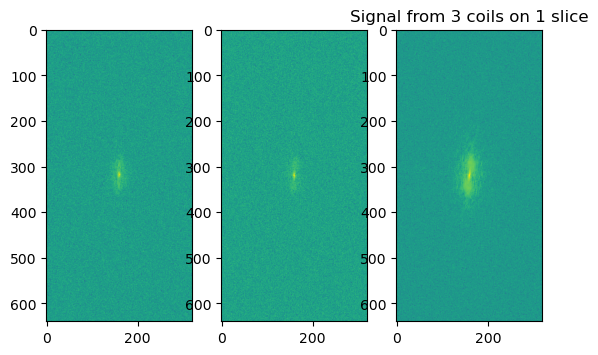

In [100]:
middle_index = volume_kspace.shape[0] //2
slice_kspace = volume_kspace[middle_index] # Choosing the middle slice of this volume

def show_coils(data, slice_nums, cmap=None):
    fig = plt.figure()
    for i, num in enumerate(slice_nums):
        plt.subplot(1, len(slice_nums), i + 1)
        plt.imshow(data[num], cmap=cmap)

show_coils(np.log(np.abs(slice_kspace) + 1e-9), [0, 5, 10])  # This shows coils 0, 5 and 10
# Note that a small constant is added for numerical stability.
plt.title("Signal from 3 coils on 1 slice")

### Showing the 20 coils signal separately for 1 slice (middle slice from 16 one) 

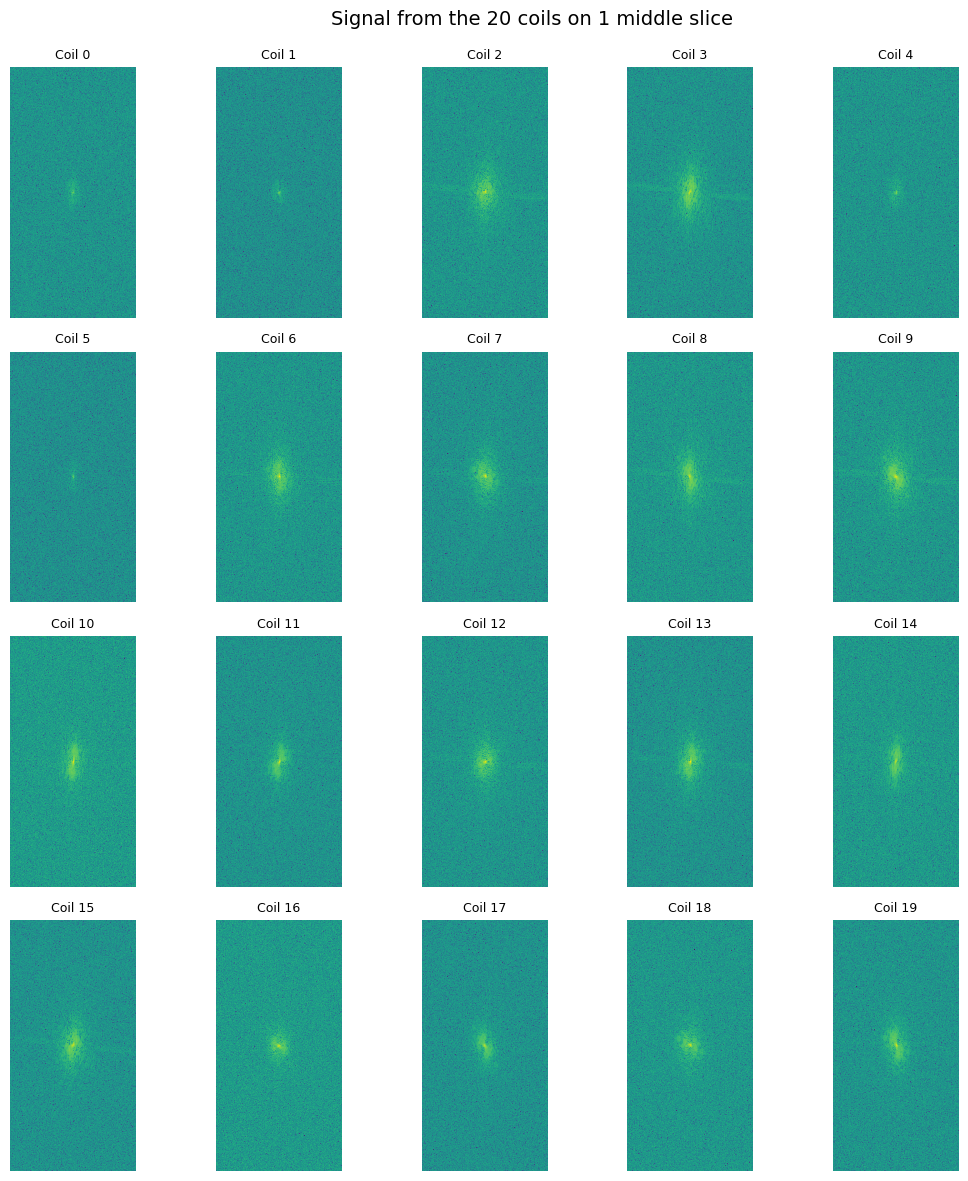

In [139]:
def show_coils_grid(data, coil_indices=None, cmap='viridis', nrows=4, ncols=5, fig_size=(12,9)):
    if coil_indices is None:
        coil_indices = list(range(data.shape[0]))
    fig, axes = plt.subplots(nrows, ncols, figsize=fig_size)
    axes = axes.flatten()
    # consistent color scaling across all coils
    vals = np.array([data[i] for i in coil_indices])
    vmin = vals.min()
    vmax = vals.max()
    im = None
    for ax, idx in zip(axes, coil_indices):
        im = ax.imshow(data[idx], cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(f'Coil {idx}', fontsize=9)
        ax.axis('off')
    # turn off any unused axes
    for ax in axes[len(coil_indices):]:
        ax.axis('off')
    fig.tight_layout(rect=[0,0,0.92,0.96])
    fig.suptitle('Signal from the 20 coils on 1 middle slice', fontsize=14)


# display log-magnitude of k-space (small constant to avoid log(0))
data_to_show = np.log(np.abs(slice_kspace) + 1e-9)
show_coils_grid(data_to_show, coil_indices=[i for i in range(0, 20)], cmap='viridis', nrows=4, ncols=5, fig_size=(12,12))

### Showing the reconstructed images from 3 coils signal separately for 1 slice (middle slice from 16 one) 

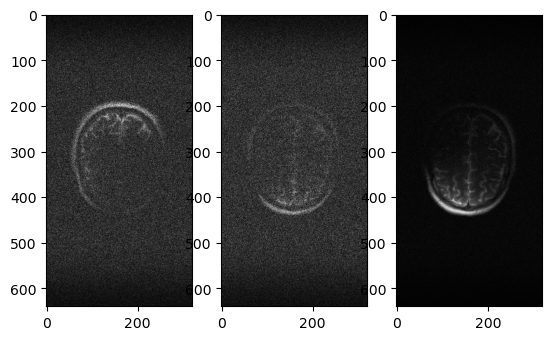

In [101]:
def inverse_fft2_shift(kspace):
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace, axes=(-2,-1)), norm='ortho'),axes=(-2,-1))

show_coils(np.abs(inverse_fft2_shift(slice_kspace)), [0, 5, 10], cmap='gray')  # This shows coils 0, 5 and 10


### Showing the reconstructed images from 20 coils signal separately for 1 slice (middle slice from 16 one) 

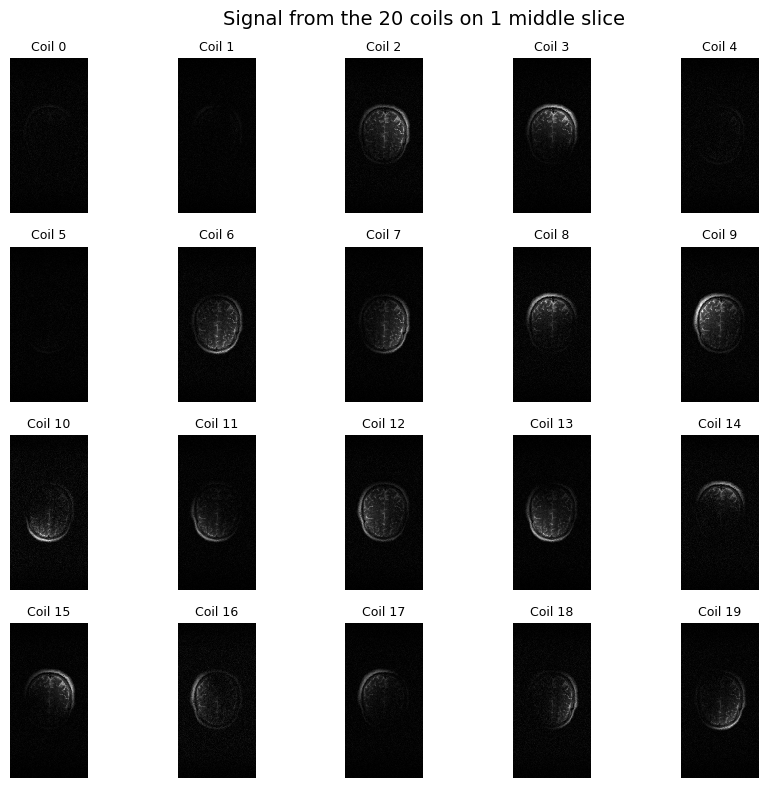

In [140]:
show_coils_grid(np.abs(inverse_fft2_shift(slice_kspace)), coil_indices=[i for i in range(0, 20)], cmap='gray', nrows=4, ncols=5, fig_size=(10,8))

### Combining signal from the 20 coils on the middle slice

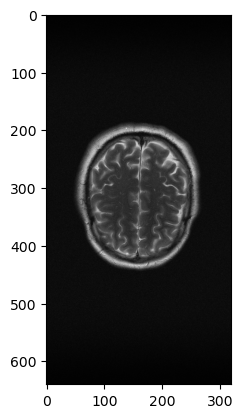

In [46]:
# Combine multi-coil data using Root Sum of Squares (RSS) to create magnitude image
magnitude_slice = np.sqrt(np.sum(np.abs(inverse_fft2_shift(slice_kspace))**2, axis=0))
plt.imshow(magnitude_slice, cmap='gray')

In [123]:
number_of_slices = volume_kspace.shape[0]
number_of_slices

16

### Combining signal from the 20 coils on the 16 slices

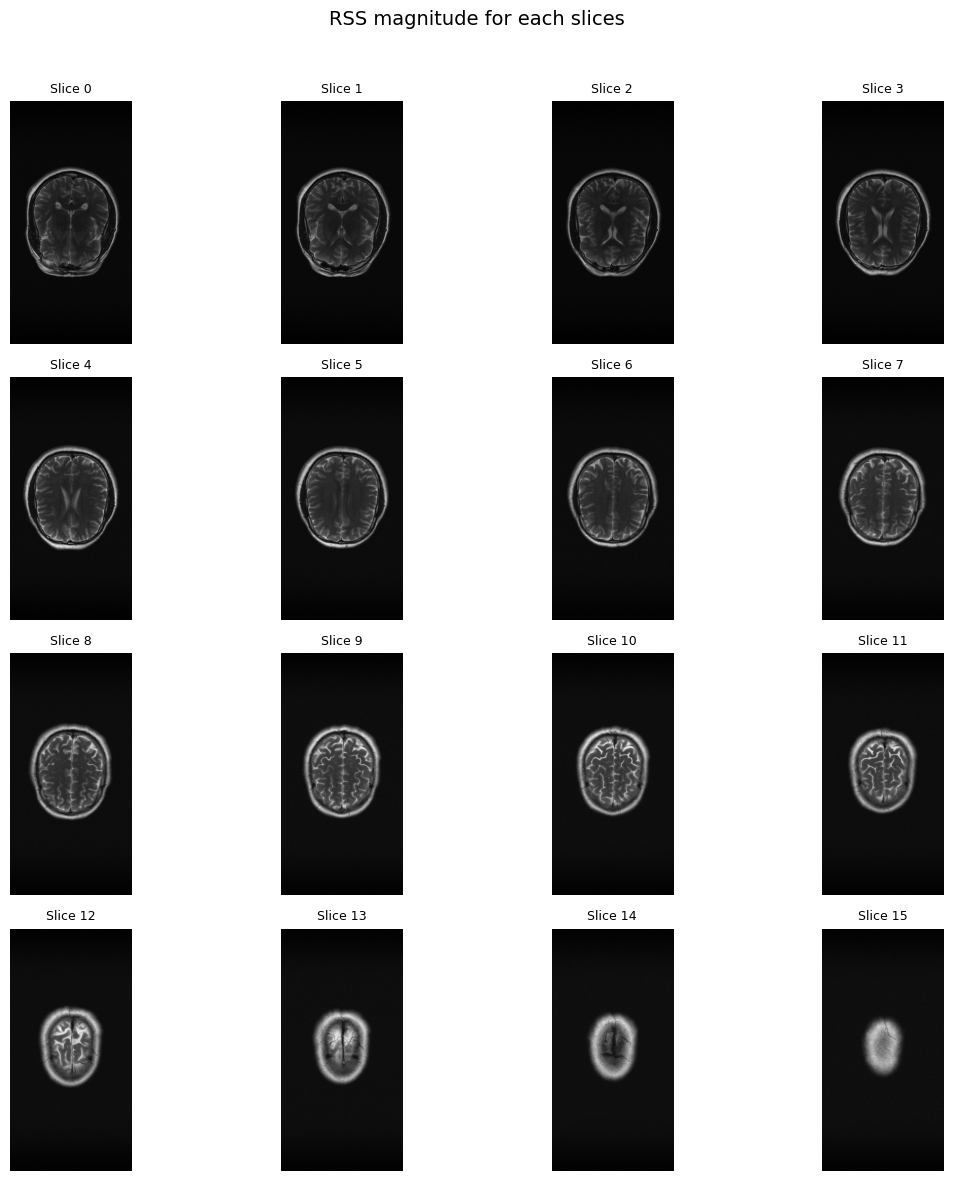

In [141]:
# Plot all 16 slices in a 4x4 grid (RSS magnitude)
number_of_slices = volume_kspace.shape[0]
fig, axes = plt.subplots(4, 4, figsize=(12,12))
axes = axes.flatten()
for idx, ax in enumerate(axes):
    if idx >= number_of_slices:
        ax.axis('off')
        continue
    # compute RSS magnitude for slice idx
    ksp = volume_kspace[idx]
    img_coils = inverse_fft2_shift(ksp)
    magnitude_slice = np.sqrt(np.sum(np.abs(img_coils)**2, axis=0))
    ax.imshow(magnitude_slice, cmap='gray')
    ax.set_title(f'Slice {idx}', fontsize=9)
    ax.axis('off')
fig.suptitle('RSS magnitude for each slices', fontsize=14)
plt.tight_layout(rect=[0,0,1,0.96])

##  Exploring reconstruction_rss

In [29]:
image_file.keys()

<KeysViewHDF5 ['ismrmrd_header', 'kspace', 'reconstruction_rss']>

In [30]:
image_file['reconstruction_rss']

<HDF5 dataset "reconstruction_rss": shape (16, 320, 320), type "<f4">

In [31]:
reconstruction_rss = image_file['reconstruction_rss']
reconstruction_rss

<HDF5 dataset "reconstruction_rss": shape (16, 320, 320), type "<f4">

In [33]:
reconstruction_rss[8,:,:]

array([[3.8898746e-05, 5.1376541e-05, 3.6700258e-05, ..., 5.1690997e-05,
        4.6884361e-05, 4.0988842e-05],
       [4.1853909e-05, 4.0649571e-05, 5.2714655e-05, ..., 3.7173973e-05,
        3.3006319e-05, 4.1978376e-05],
       [3.8560440e-05, 3.7064987e-05, 4.4267515e-05, ..., 4.6930796e-05,
        4.1076586e-05, 3.9220617e-05],
       ...,
       [4.9134662e-05, 3.5822275e-05, 3.2133976e-05, ..., 6.3452600e-05,
        5.0631777e-05, 3.4236262e-05],
       [5.0423230e-05, 3.8983937e-05, 4.0205072e-05, ..., 4.5625668e-05,
        4.8356003e-05, 4.2775311e-05],
       [4.2391712e-05, 4.5865538e-05, 3.8040373e-05, ..., 4.0683495e-05,
        3.9276500e-05, 4.3930388e-05]], dtype=float32)

In [37]:
# mosaic function takes arguments : (img, num_row, num_col, fig_num, clim, title = '', use_transpose = False, use_flipud = False
lib.mosaic(reconstruction_rss[0:8,:,:], 2, 4, 1, [0,5e-4], 'image rss', 0, 0)

sizes do not match


UnboundLocalError: local variable 'img_res' referenced before assignment

<Figure size 640x480 with 0 Axes>